> Notebook-friendly copy of `part-I/1.6-geospatial-vector-data-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [3]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import geopandas as `gpd`, keep track of the crs at every step, and measure only after reprojecting to a metric crs.

## Exercise 1: Hurricane track analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/nasa-hurricane-florence-2018-09-11.jpg" alt="A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud" width="500">

<em>Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from <a href="https://worldview.earthdata.nasa.gov/">NASA Worldview</a> via <a href="https://commons.wikimedia.org/wiki/File:Florence_2018-09-11_1750Z.jpg">Wikimedia Commons</a>, public domain.</em>


*Can you quickly find out which US states Hurricane Florence passed through using geopandas?*

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence
from 30 August to 18 September 2018. The track is the archived advisory record from the
[National Hurricane Center](https://www.nhc.noaa.gov/); the state boundaries are a
[US Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html)
cartographic boundary file.

References:

1. [Introduction to GeoPandas](https://geopandas.org/en/stable/getting_started/introduction.html) — geopandas' official website
2. [Geopandas: an introduction](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-2/geopandas-an-introduction.html) — Automating GIS Processes
3. [Use Data for Earth and Environmental Science in Open Source Python](https://www.earthdatascience.org/courses/use-data-open-source-python/)
4. [The Shapely User Manual](https://shapely.readthedocs.io/en/stable/manual.html)
5. [Geospatial Analysis with Python and R](https://kodu.ut.ee/~kmoch/geopython2020/index.html)

In [2]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Where the tools come from**

Every tool the questions need has been demonstrated already. `read_file`, `.plot()`, `GeoDataFrame`,
`gpd.points_from_xy`, `.crs`, `geom_type`, the MultiPolygon type, `.isin()`, `overlay`, `.centroid`,
`to_crs`, `buffer` and the spatial predicates are from this subchapter's lecture; `.head()` and
boolean filtering are from 1.5, and `unique` from 1.5's earthquake exercise. `ax.annotate`, which Q8
uses to label each state, is from 1.4.

**Q1) Import geopandas and pandas.**

Import geopandas as `gpd`, pandas as `pd`, and matplotlib's pyplot as `plt`.

In [1]:
import geopandas as gpd
import pandas as pd
import  matplotlib.pyplot as plt

**Q2) Read the state boundary file with geopandas' `read_file` function.**

The file is cached at `states_path`. Call the result `country`.

In [8]:
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [13]:
print(country.head())
# Check the geometry types contained in the GeoDataFrame
print(country.geom_type.unique()) #lists the distinct geometry types present in the dataset.

# The data contains Polygon and MultiPolygon geometries.
# Some US states consist of multiple separate land areas or islands,
# so they are represented as MultiPolygons.

        GEO_ID STATE        NAME LSAD  CENSUSAREA  \
0  0400000US01    01     Alabama        50645.326   
1  0400000US02    02      Alaska       570640.950   
2  0400000US04    04     Arizona       113594.084   
3  0400000US05    05    Arkansas        52035.477   
4  0400000US06    06  California       155779.220   

                                            geometry  
0  MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ...  
1  MULTIPOLYGON (((-166.10574 53.98861, -166.0752...  
2  POLYGON ((-112.53859 37.00067, -112.53454 37.0...  
3  POLYGON ((-94.04296 33.01922, -94.04304 33.079...  
4  MULTIPOLYGON (((-122.42144 37.86997, -122.4213...  
['MultiPolygon' 'Polygon']


**Q4) Have a look at the data on a map using geopandas' `.plot()` method.**

Exclude Alaska and Hawaii using the `NAME` attribute and pandas' `.isin()` method. Specify the
figsize to be 30 x 20.

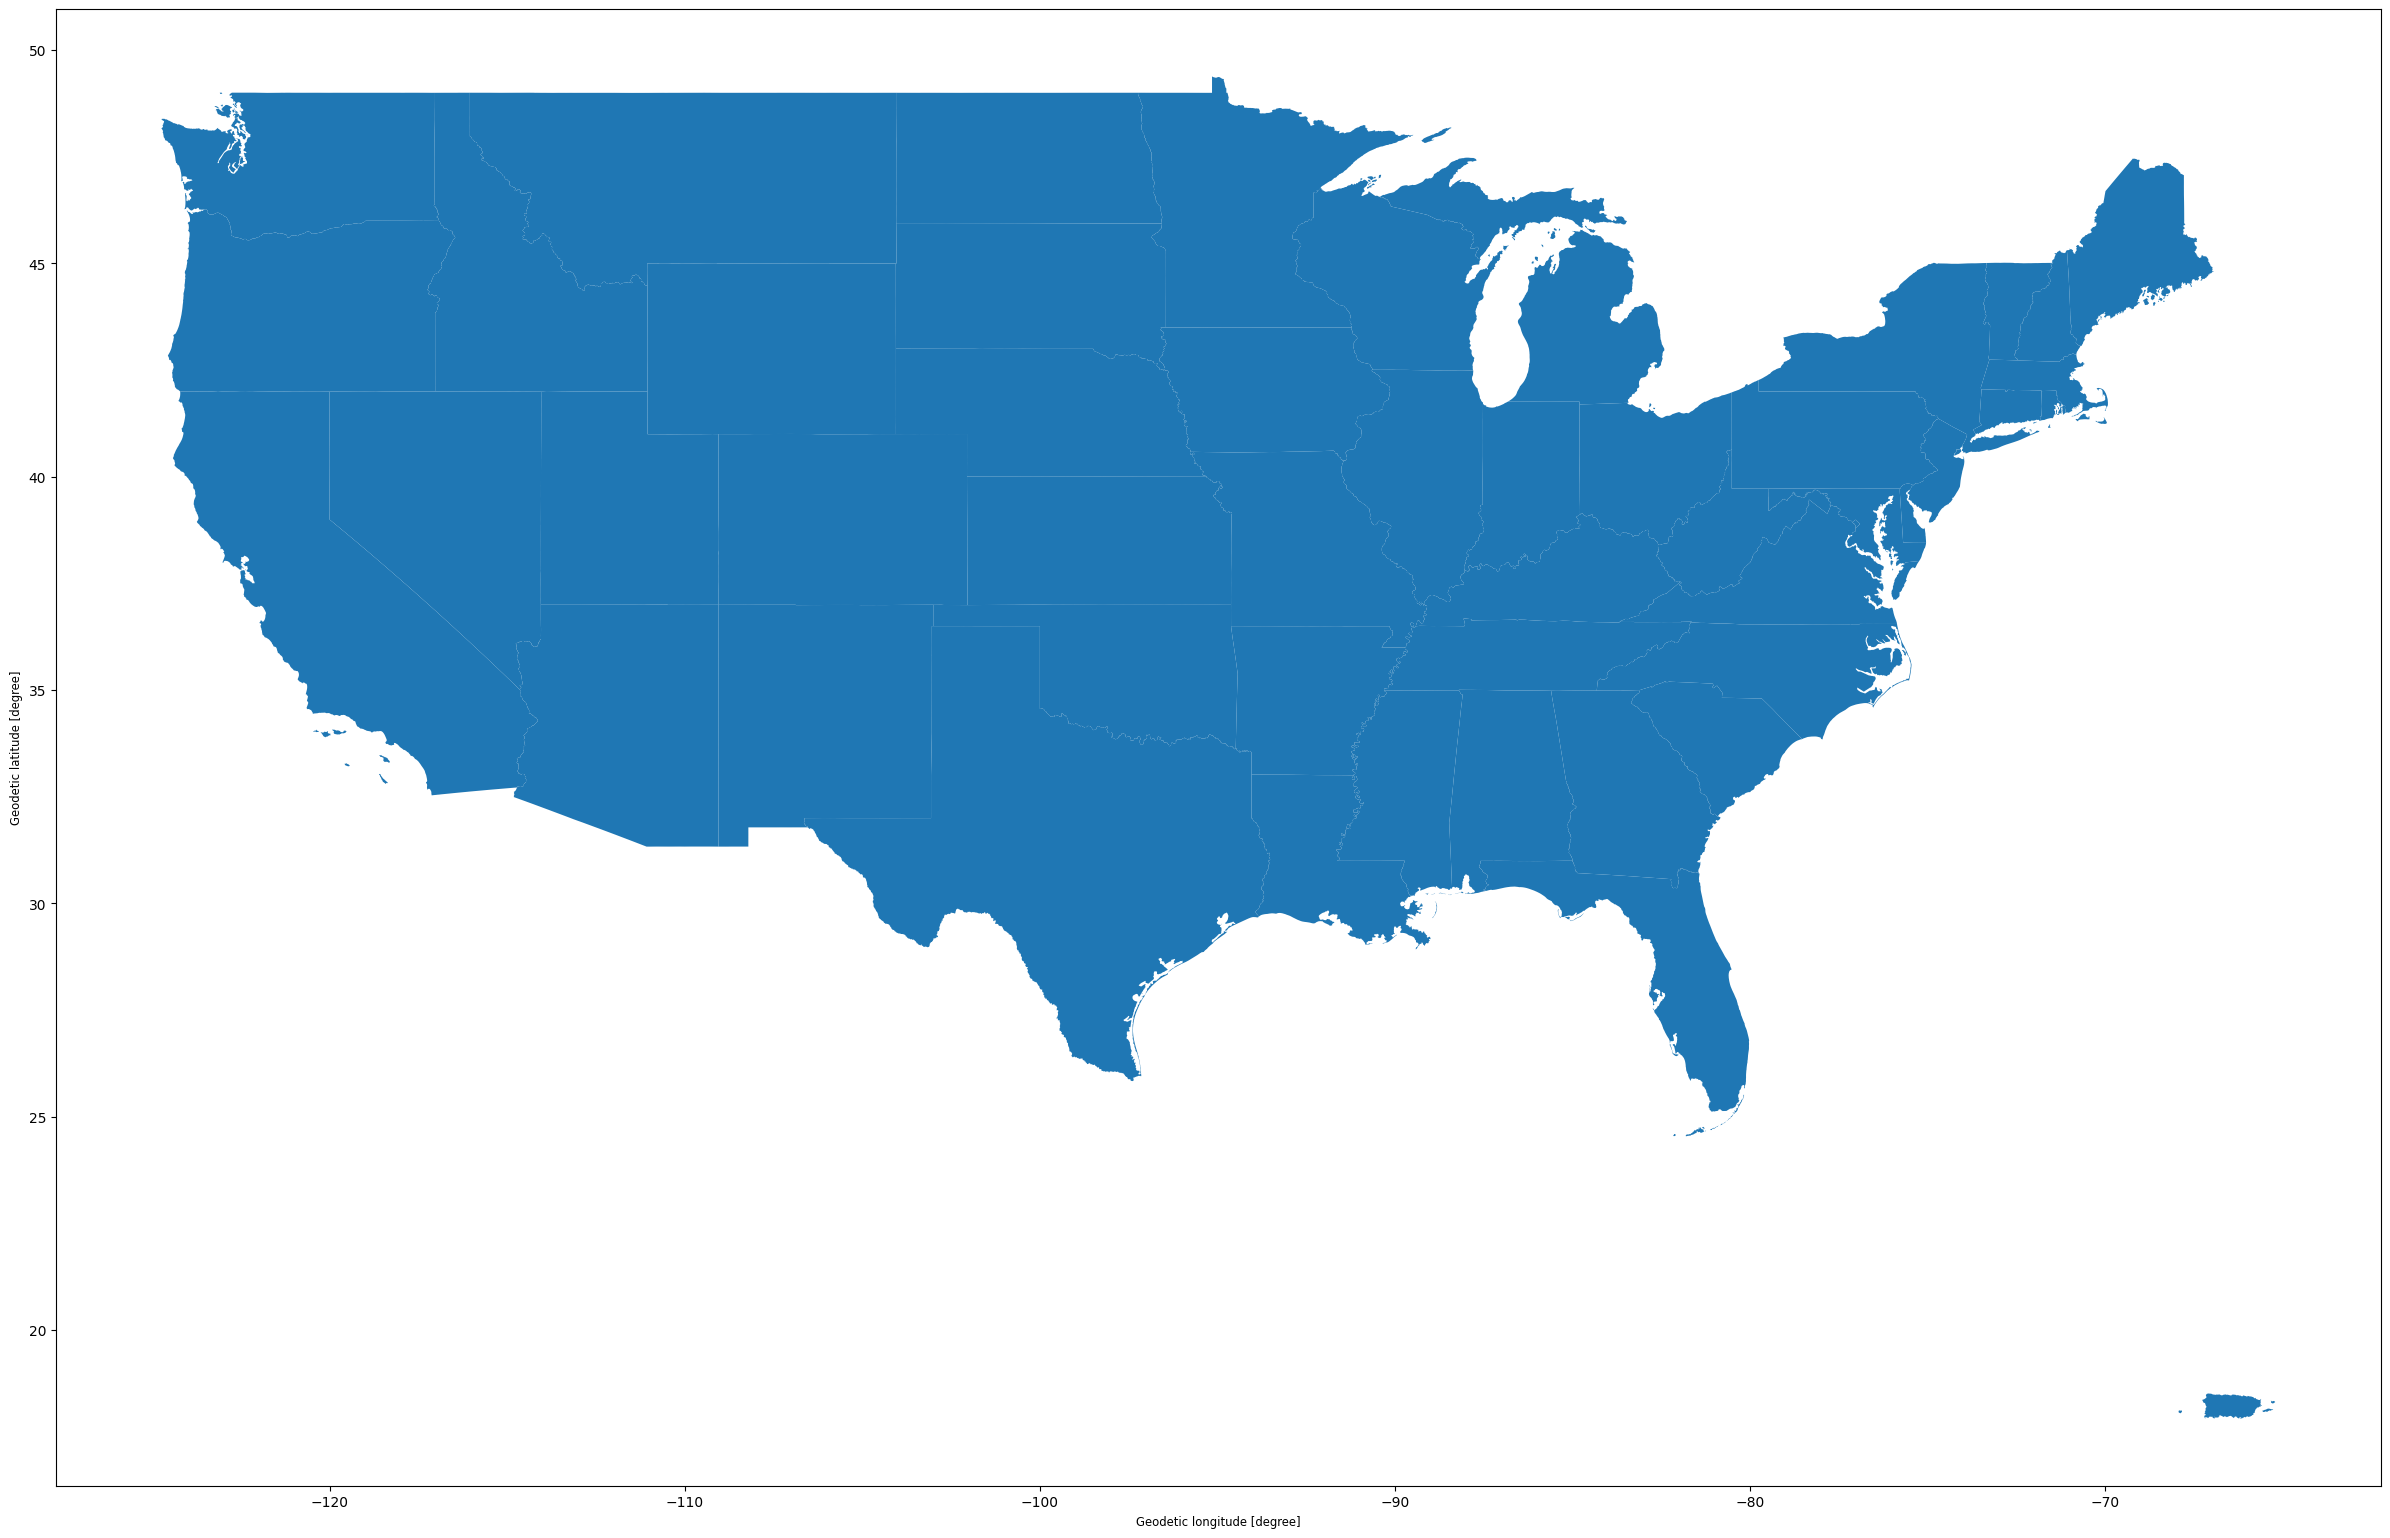

In [16]:
# Exclude Alaska and Hawaii from the dataset
country_mainland = country[~country["NAME"].isin(["Alaska", "Hawaii"])]
#country["NAME"].isin(["Alaska", "Hawaii"]) returns True for Alaska and Hawaii.
#~ reverses the Boolean values, keeping all other states.
# Plot the map of the remaining states with a figure size of 30 x 20
country_mainland.plot(figsize=(30, 20))

# Display the map
plt.show()

In [17]:
# Pre-supplied: read in the hurricane Florence data, drop the advisory bookkeeping columns,
# fix the longitude sign, and have a look at the dataframe.
# The Long column holds a positive "degrees west" magnitude, not a signed longitude -- a common
# quirk of NHC advisory data.
florence = pd.read_csv(track_path)
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
#removes columns or rows from a DataFrame
florence["Long"] = 0 - florence["Long"]
florence.head(3)

,Date,Lat,Long,Wind,Pres,Movement,Type,Name
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six


**Q5) Create a GeoDataFrame from the `florence` DataFrame.**

Build the geometry column from the `Long` and `Lat` columns with
[`gpd.points_from_xy`](https://geopandas.org/en/stable/docs/reference/api/geopandas.points_from_xy.html),
and call the result `gdf_florence`. Then look at its first few rows.

In [20]:
# Create a GeoDataFrame from the Florence DataFrame
gdf_florence = gpd.GeoDataFrame(
    florence,
    # Create point geometries using longitude and latitude
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326",  # WGS84 longitude/latitude in degrees
)

# Display the first few rows
gdf_florence.head()

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry
0,08/30/2018 11:00,12.9,-18.4,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-18.4 12.9)
1,08/30/2018 14:00,12.9,-19.0,30,1007,W at 12 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19 12.9)
2,08/30/2018 17:00,12.9,-19.4,30,1007,W at 9 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-19.4 12.9)
3,08/30/2018 20:00,13.1,-20.4,30,1007,W at 11 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.4 13.1)
4,08/30/2018 23:00,13.2,-20.9,35,1007,W at 13 MPH (280 deg),Potential Tropical Cyclone,Six,POINT (-20.9 13.2)


**Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

Draw the states as a base map, then plot the hurricane positions on top in a colour that stands
out.

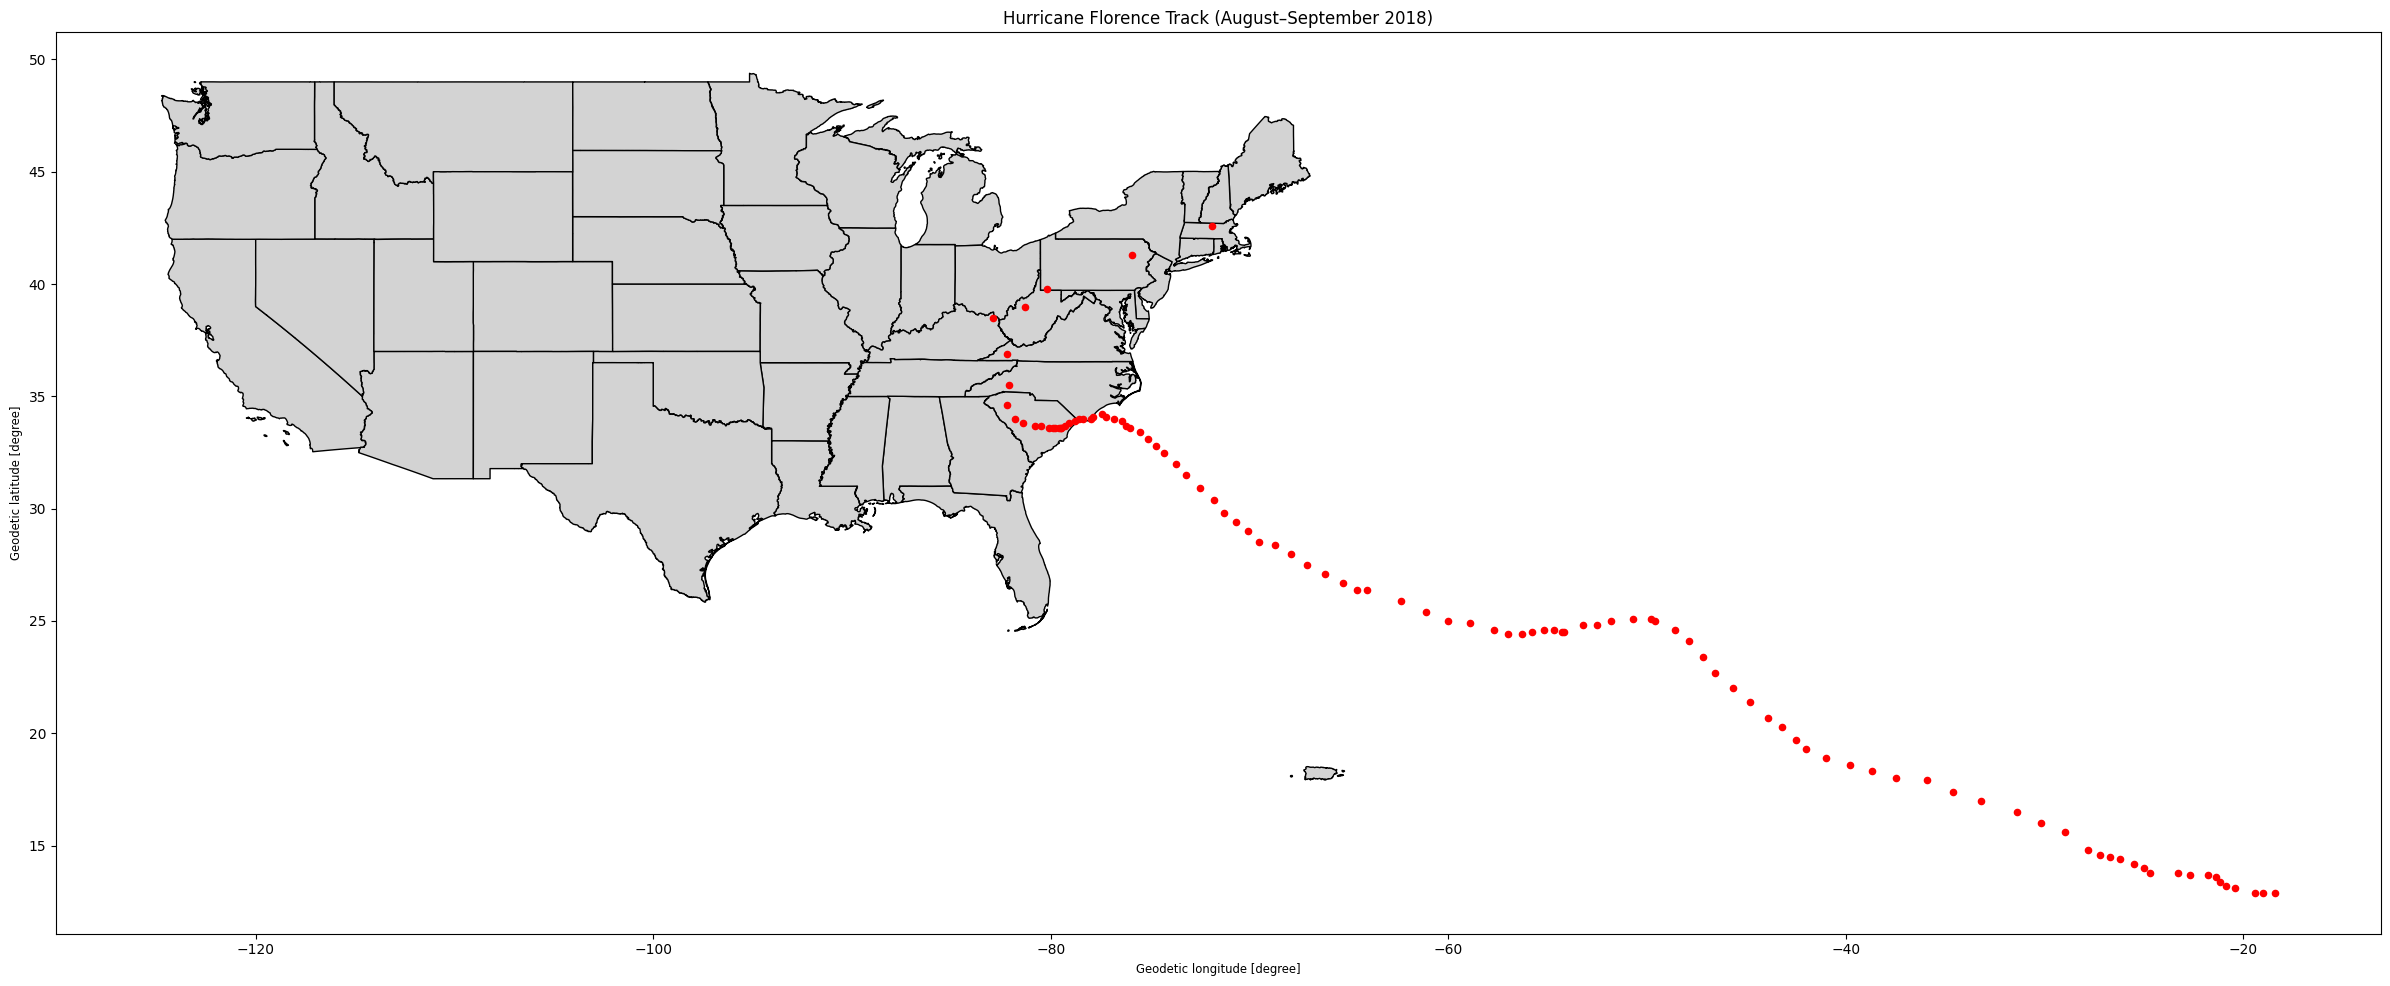

In [22]:
# Create a figure and axes
fig, ax = plt.subplots(figsize=(30, 20))

# Plot the US states as the base map, excluding Alaska and Hawaii
country_mainland.plot(ax=ax, color="lightgray", edgecolor="black")

# Plot Hurricane Florence positions on top in a contrasting colour
gdf_florence.plot(ax=ax, color="red", markersize=20)

# Add a title
ax.set_title("Hurricane Florence Track (August–September 2018)")

# Display the map
plt.show()
#ax=ax tells GeoPandas to draw the plot on the same axes as the previous plot, allowing you to layer one dataset on top of another.

**Q7) What is the coordinate reference system of the data?**

Check it for both layers, and say in a comment whether they match — two layers only line up on
one pair of axes if they share a crs.

In [25]:
# Check the CRS of the US states layer
print("US states CRS:", country_mainland.crs)

# Check the CRS of the Hurricane Florence layer
print("Hurricane Florence CRS:", gdf_florence.crs)

# Both layers use EPSG:4326 (WGS84), so their CRS match.
# They can therefore be plotted together on the same axes without reprojection.

US states CRS: EPSG:4326
Hurricane Florence CRS: EPSG:4326


**Q8) Which states did the hurricane pass through?**

**ℹ️ Hint**

One approach is to plot the trajectory over the US map, annotate each state with its name, and
read the answer off the figure. Other approaches are more than welcome — `overlay` with
`how="intersection"` will give you the track points that fall inside a state polygon, and the
`NAME` column of the result then answers the question directly.

In [26]:
states = gdf_florence.overlay(country_mainland, how="intersection")
# Get the unique state names from the NAME column
states_passed = states["NAME"].unique()

# Print the states Hurricane Florence passed through
print(states_passed)

# The intersection identifies the states containing the recorded hurricane positions

['North Carolina' 'South Carolina' 'Virginia' 'Kentucky' 'West Virginia'
 'Pennsylvania' 'Massachusetts']


BONUS:

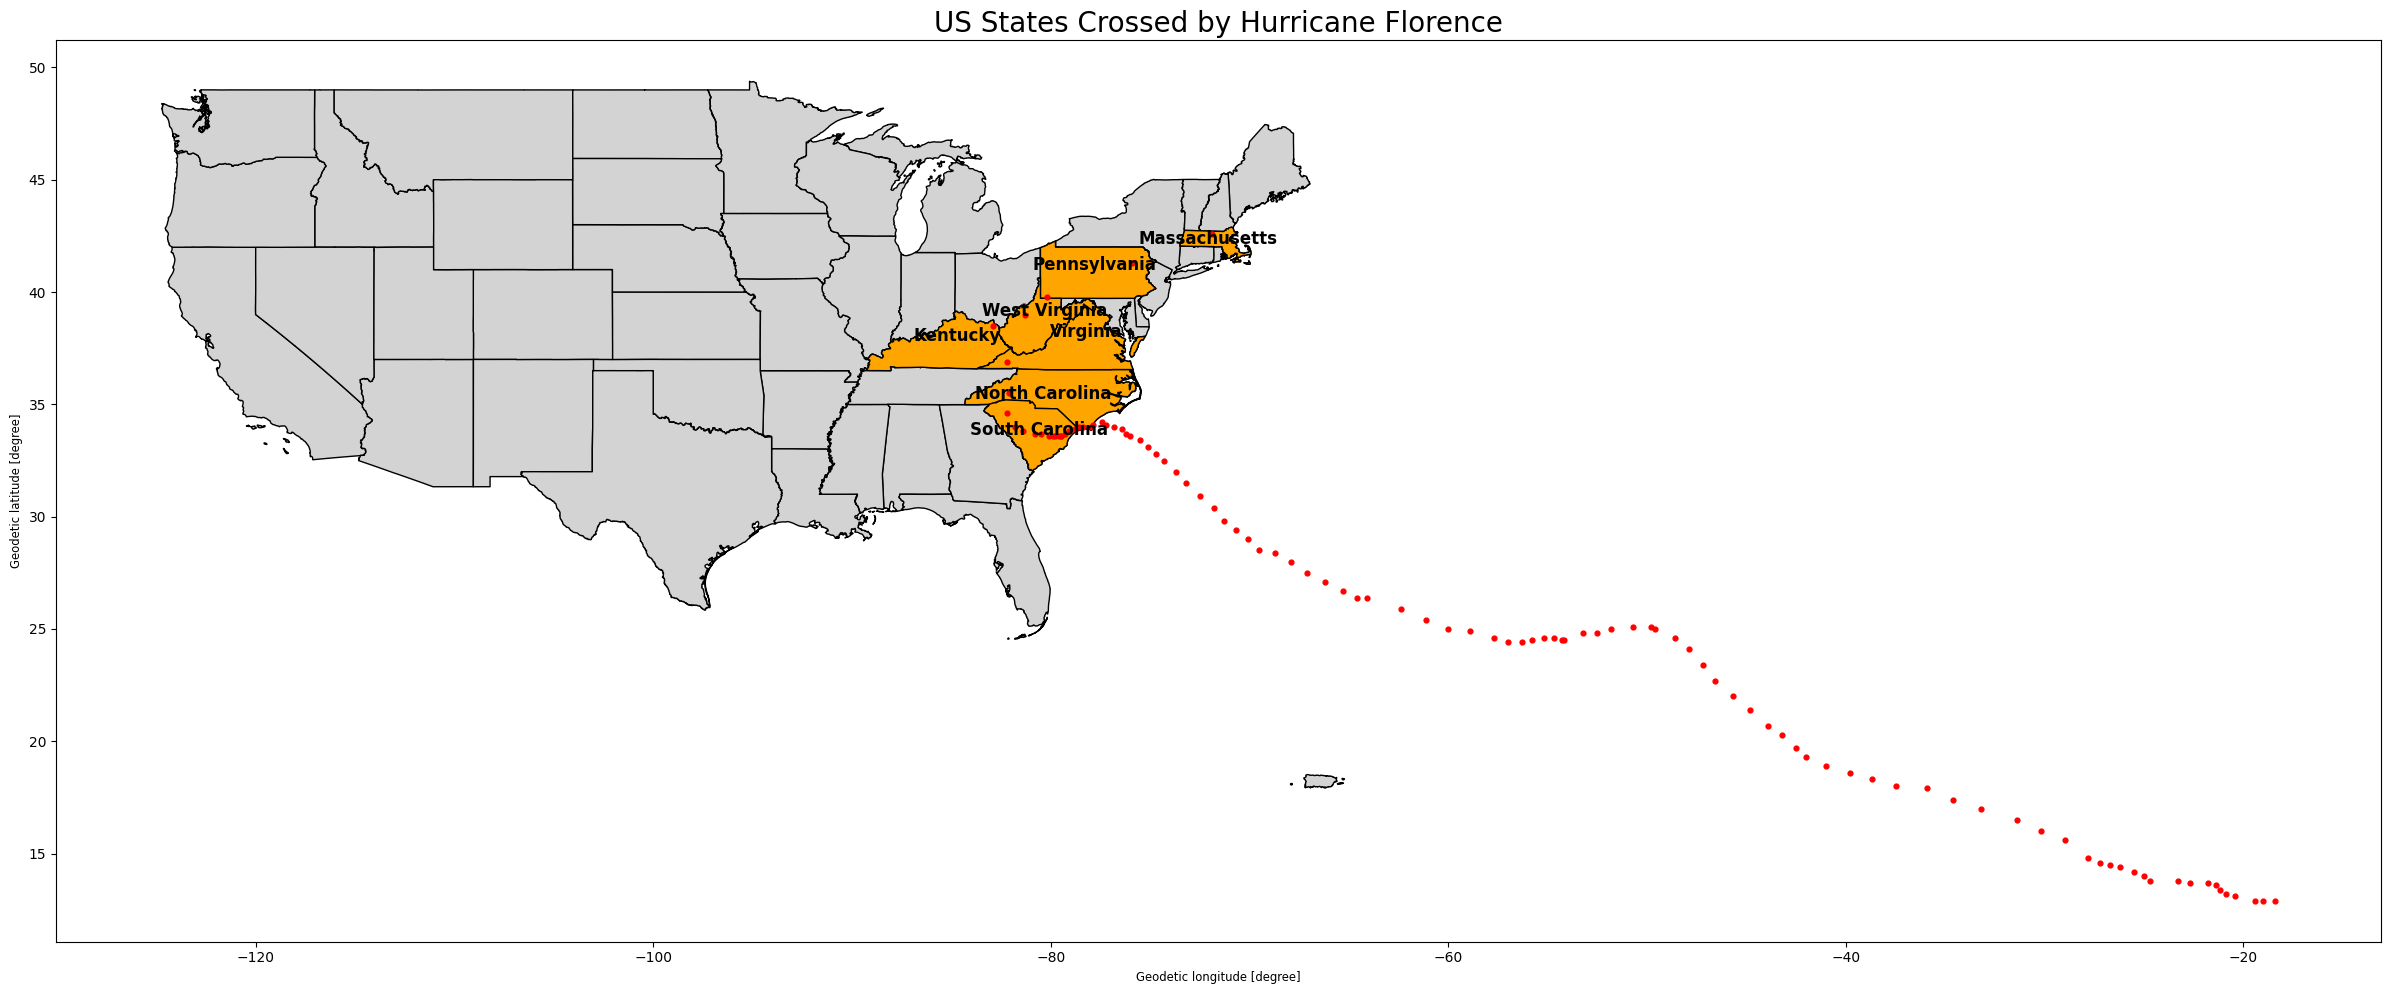

In [29]:
# Find the unique states crossed by Hurricane Florence
states_passed = states["NAME"].unique()

# Keep only those states in the US map
passed_states = country_mainland[country_mainland["NAME"].isin(states_passed)]

# Create a large figure
fig, ax = plt.subplots(figsize=(30, 20))

# Plot all US states as the base map
country_mainland.plot(ax=ax, color="lightgray", edgecolor="black")

# Highlight the states crossed by Florence
passed_states.plot(ax=ax, color="orange", edgecolor="black")

# Add names only for the states crossed by Florence
for index, row in passed_states.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        text=row["NAME"],
        xy=(point.x, point.y),
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Plot Hurricane Florence positions on top in red
gdf_florence.plot(ax=ax, color="red", markersize=12)

# Add a title and display the map
ax.set_title("US States Crossed by Hurricane Florence", fontsize=20)
plt.show()